In [1]:
pip install shap joblib

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 9.4 MB/s  0:00:00
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]━━━━━━━━━━━━━ 2/3 [shap]
Note: you may need to restart the kernel to use updated packages.


In [8]:
# Step 1 — Load your selected model
import joblib
from pathlib import Path

best_model = joblib.load("best_model.pkl")
Path("../models").mkdir(exist_ok=True)

joblib.dump(
    best_model,
    "../models/best_credit_risk_model.joblib"
)

['../models/best_credit_risk_model.joblib']

In [9]:
import joblib
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

best_model = joblib.load(
    "../models/best_credit_risk_model.joblib"
)

print(best_model)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'AGE', 'PAY_1',
                                                   'PAY_2', 'PAY_3', 'PAY_4',
                                                   'PAY_5', 'PAY_6',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                

In [10]:
# Step 2 — Load your cleaned dataset

from sklearn.model_selection import train_test_split

df = pd.read_csv(
    "../data/processed/credit_card_cleaned.csv"
)

X = df.drop(columns=["ID", "default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pay_cols = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

def add_features(X):
    X = X.copy()

    X["months_with_delay"] = (
        X[pay_cols] > 0
    ).sum(axis=1)

    X["max_delay"] = (
        X[pay_cols].clip(lower=0).max(axis=1)
    )

    return X

X_train = add_features(X_train)
X_test = add_features(X_test)

print(X_test.shape)


(6000, 25)


In [11]:
# Step 3 — Prepare the data for SHAP

preprocessor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

# Use a small sample for faster explanations
X_sample = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

X_transformed = preprocessor.transform(X_sample)

if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_shap = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_sample.index
)

print("SHAP input shape:", X_shap.shape)
display(X_shap.head())


SHAP input shape: (200, 32)


,num__LIMIT_BAL,num__AGE,num__PAY_1,num__PAY_2,num__PAY_3,num__PAY_4,num__PAY_5,num__PAY_6,num__BILL_AMT1,num__BILL_AMT2,...,cat__SEX_1,cat__SEX_2,cat__EDUCATION_1,cat__EDUCATION_2,cat__EDUCATION_3,cat__EDUCATION_4,cat__MARRIAGE_0,cat__MARRIAGE_1,cat__MARRIAGE_2,cat__MARRIAGE_3
20639,0.715283,0.170458,0.012576,0.111849,2.652046,1.911811,2.017773,2.002137,1.529789,2.028720,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7660,-0.674586,0.931736,1.793311,0.111849,0.139780,0.190493,-1.537252,-1.489963,0.378861,0.434448,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
13980,1.487433,-0.590820,-1.768158,-1.556496,-1.535065,-1.530826,-1.537252,-1.489963,-0.684962,-0.675426,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7162,-0.597371,-1.025836,1.793311,0.111849,0.139780,0.190493,0.240260,0.256087,0.528463,0.605838,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
24017,-0.906231,-1.134590,-0.877791,-0.722324,-0.697642,-0.670167,0.240260,0.256087,-0.616072,-0.692917,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [12]:
# Step 4 — Create the SHAP explainer

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

if isinstance(classifier, RandomForestClassifier):
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer(X_shap)

elif isinstance(classifier, LogisticRegression):
    background = preprocessor.transform(
        X_train.sample(
            n=min(500, len(X_train)),
            random_state=42
        )
    )

    if hasattr(background, "toarray"):
        background = background.toarray()

    explainer = shap.LinearExplainer(
        classifier,
        background
    )

    shap_values = explainer(X_shap)

else:
    raise ValueError(
        "This example supports Random Forest "
        "and Logistic Regression."
    )

print("SHAP values shape:", shap_values.values.shape)


SHAP values shape: (200, 32, 2)


In [13]:

if shap_values.values.ndim == 3:
    shap_default = shap_values[:, :, 1]
else:
    shap_default = shap_values

print("Default explanation shape:", shap_default.values.shape)


Default explanation shape: (200, 32)


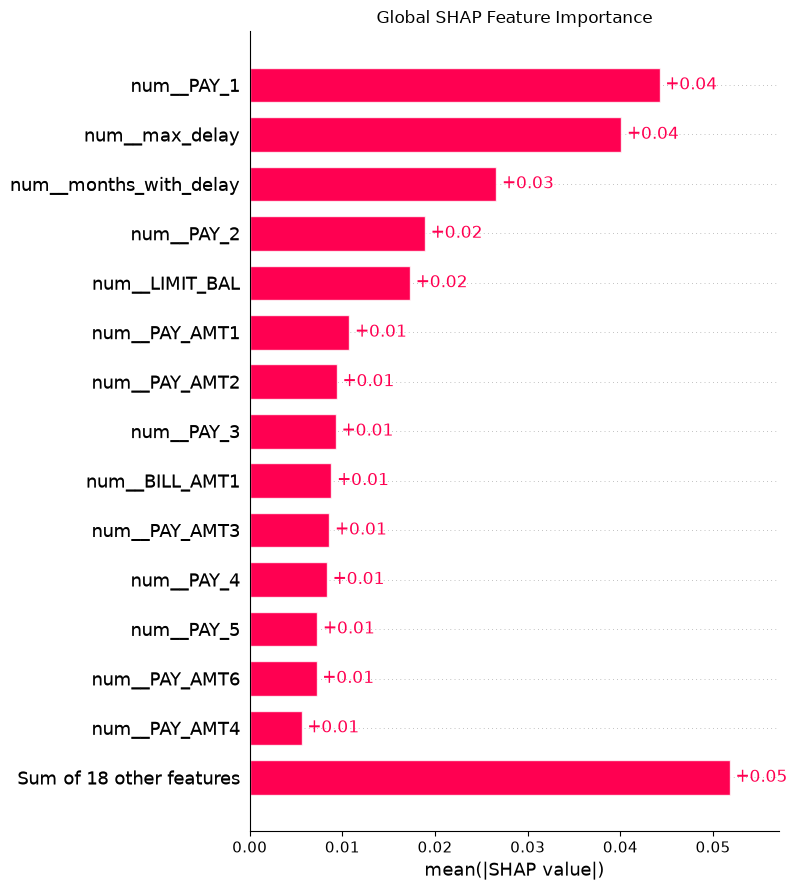

In [14]:
# Step 5 — Global feature importance plot

shap.plots.bar(
    shap_default,
    max_display=15,
    show=False
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()


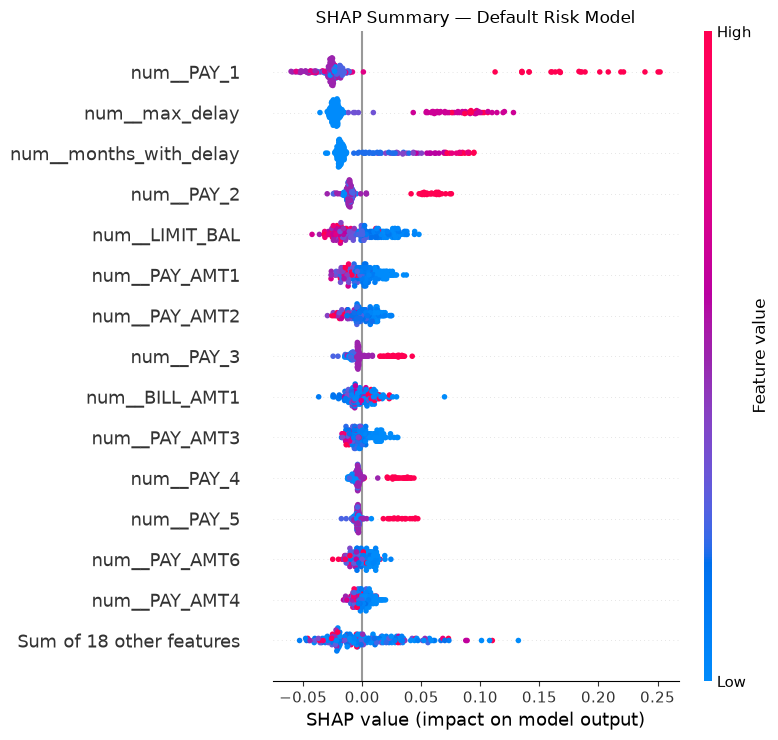

In [15]:
# Step 6 — SHAP beeswarm plot

shap.plots.beeswarm(
    shap_default,
    max_display=15,
    show=False
)

plt.title("SHAP Summary — Default Risk Model")
plt.tight_layout()
plt.show()


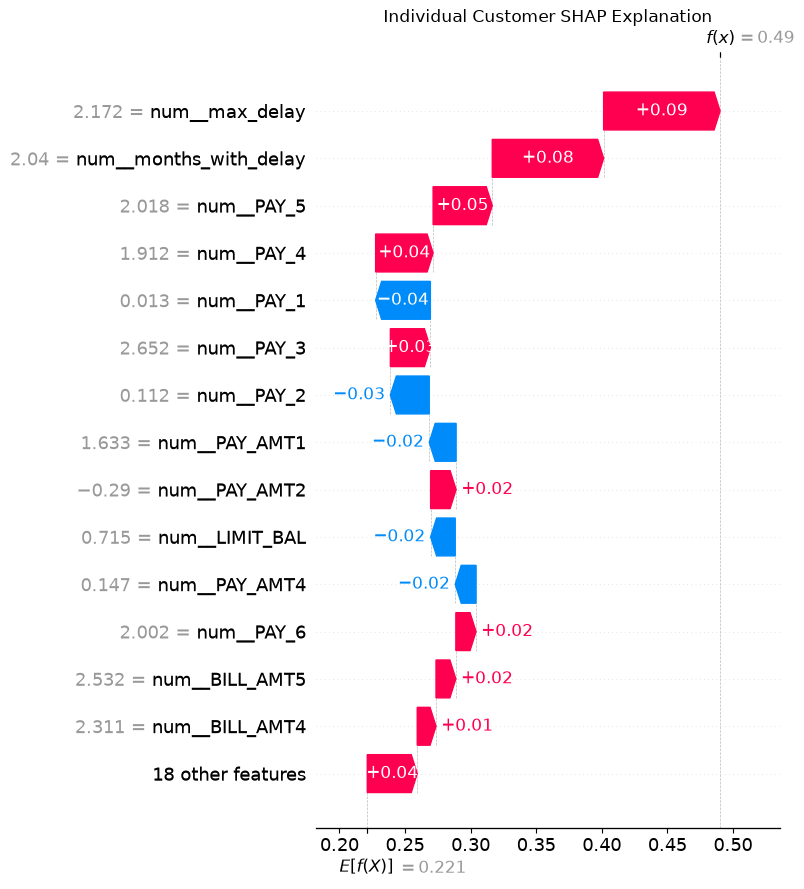

In [16]:
# Step 7 — Explain an individual customer

customer_position = 0

shap.plots.waterfall(
    shap_default[customer_position],
    max_display=15,
    show=False
)

plt.title("Individual Customer SHAP Explanation")
plt.tight_layout()
plt.show()


In [17]:
# display that customer's predicted default probability

customer = X_sample.iloc[[customer_position]]

predicted_probability = (
    best_model.predict_proba(customer)[0, 1]
)

print(
    "Predicted default probability:",
    f"{predicted_probability:.2%}"
)

display(customer)


Predicted default probability: 49.02%


,LIMIT_BAL,SEX,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,EDUCATION,MARRIAGE,months_with_delay,max_delay
20639,260000.0,1,37,0,0,3,2,2,2,163553.0,...,32000.0,0.0,7100.0,7000.0,6500.0,7000.0,1,1,4,3


In [18]:
# Step 8 — Save the plots for your portfolio

from pathlib import Path

Path("../reports/figures").mkdir(
    parents=True,
    exist_ok=True
)

shap.plots.bar(
    shap_default,
    max_display=15,
    show=False
)

plt.savefig(
    "../reports/figures/shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


In [21]:
# Save the SHAP Beeswarm Plot

Path("../reports/figures").mkdir(
    parents=True,
    exist_ok=True
)

# Generate beeswarm plot
shap.plots.beeswarm(
    shap_default,
    max_display=15,
    show=False
)

plt.title("SHAP Beeswarm Plot")

# Save the plot
plt.savefig(
    "../reports/figures/shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()


In [22]:
# Save the SHAP Waterfall Plot

# Select one customer
customer_position = 0

# Generate waterfall plot
shap.plots.waterfall(
    shap_default[customer_position],
    max_display=15,
    show=False
)

plt.title("SHAP Waterfall Plot - Individual Customer")

# Save the plot
plt.savefig(
    "../reports/figures/shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

In [23]:
# Verify that all three plots are saved

from pathlib import Path

figures_folder = Path("../reports/figures")

for file in figures_folder.glob("shap_*.png"):
    print(file.name)


shap_beeswarm.png
shap_global_importance.png
shap_waterfall.png
